# Wheat prices, climate and market sentiment: from data to a trading strategy

**Goal.** Explain and forecast monthly wheat price changes with climate (El Niño / La Niña), market sentiment extracted from USDA reports (NLP), the US dollar and oil prices, then use the forecasts to manage a position on wheat under a risk constraint.

| Variable | Source | Native frequency |
|---|---|---|
| `wheat` — wheat price (USD/t) | IMF, series PWHEAMT | monthly |
| `sentiment` — net tone of the wheat paragraph of the WASDE reports | USDA WASDE reports (PDF), word lists | ~1 report per month |
| `roni` — Relative Oceanic Niño Index (°C), El Niño / La Niña indicator | NOAA Climate Prediction Center | monthly (3-month average) |
| `dollar` — trade-weighted US dollar index | FRED: DTWEXM (until 2019) spliced with DTWEXBGS | daily |
| `wti` — WTI crude oil price (USD/barrel) | FRED: DCOILWTICO | daily |

**Outline.** 1. Data loading · 2. Data quality · 3. Data formatting · 4. Exploratory analysis · 5. Model · 6. Portfolio

**Running the notebook.** Downloaded and processed data are cached in `data/cache_final/`. With the cache, the notebook only needs `numpy`, `pandas`, `matplotlib` and `scikit-learn`. Without it, the download functions also use `requests`, `lxml`, `beautifulsoup4` and `pypdf`; they are imported inside these functions only.

**Origin.** This notebook merges `Wheat_Data.ipynb` (data extraction, WASDE crawler, NLP sentiment, El Niño / La Niña features, first portfolio backtest) and `Wheat_analysis.ipynb` (data quality, formatting, correlations, model, walk-forward portfolio). It corrects two issues of the first version:
- **WASDE dates.** File names mix three date formats, so reports were often assigned to the wrong month. They are now dated with the date printed in the report.
- **Timing of the backtest.** Positions only use information available before the trade.

A transformer sentiment model (FinBERT) was also tested in `Wheat_Data.ipynb`. Like the word-list score, its correlation with the next-month wheat return was close to zero, and it requires heavy extra packages, so the simpler word-list score is kept.

In [1]:
import logging
import re
import time
from io import StringIO
from pathlib import Path
from urllib.parse import urljoin

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LassoCV, LinearRegression, RidgeCV
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

DATA_DIR = Path("data")
CACHE_DIR = DATA_DIR / "cache_final"        # downloaded / processed data (delete the folder to refresh)
WASDE_DIR = DATA_DIR / "wasde_txt_reports"  # WASDE PDF reports (downloaded if the folder has none)
CACHE_DIR.mkdir(parents=True, exist_ok=True)
WASDE_DIR.mkdir(parents=True, exist_ok=True)
START = "1992-01-01"

VARS = ["wheat", "sentiment", "roni", "dollar", "wti"]
PRICES = ["wheat", "dollar", "wti"]          # trending series, studied through their log changes
COLORS = {"wheat": "#2a78d6", "sentiment": "#eb6834", "roni": "#1baf7a", "dollar": "#d99a00", "wti": "#d55181"}
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlelocation": "left", "legend.frameon": False, "font.size": 10})

## 1. Data loading

### 1.1 Market and climate data
Each series is downloaded once and stored as a CSV file in the cache folder.

In [2]:
def cached(name, download):
    """Read `name` from the cache folder, or build it with `download()` and save it first."""
    path = CACHE_DIR / name
    if not path.exists():
        download().to_csv(path, index=False)
    return pd.read_csv(path, parse_dates=["date"])


def fetch_imf_wheat():
    """Monthly wheat price from the IMF primary commodity prices database (SDMX JSON API)."""
    import requests
    url = ("https://api.imf.org/external/sdmx/3.0/data/dataflow/IMF.RES/PCPS/9.0.0/*.PWHEAMT.USD.M"
           "?c%5BTIME_PERIOD%5D=ge:1956-12-31&attributes=all&detail=full&includeHistory=true&limit=100")
    response = requests.get(url, headers={"Accept": "application/vnd.sdmx.data+json;version=2.0.0"}, timeout=60)
    response.raise_for_status()
    data = response.json()["data"]
    periods = data["structures"][0]["dimensions"]["observation"][0]["values"]
    (series,) = data["dataSets"][0]["series"].values()          # exactly one series is expected
    obs = series["observations"]
    return pd.DataFrame({"date": [pd.to_datetime(periods[int(i)]["value"].replace("-M", "-")) for i in obs],
                         "wheat": pd.to_numeric([v[0] for v in obs.values()])}).sort_values("date")


SEASON_END = {"DJF": 2, "JFM": 3, "FMA": 4, "MAM": 5, "AMJ": 6, "MJJ": 7,
              "JJA": 8, "JAS": 9, "ASO": 10, "SON": 11, "OND": 12, "NDJ": 1}

def fetch_roni():
    """RONI table of the NOAA website, one value per 3-month season, dated by the last month of the season."""
    import requests
    page = requests.get("https://www.cpc.ncep.noaa.gov/products/analysis_monitoring/enso/roni/", timeout=60)
    page.raise_for_status()
    # the RONI table is the one whose columns are the seasons DJF ... NDJ
    table = next(t for t in pd.read_html(StringIO(page.text))
                 if {"DJF", "NDJ"} <= {str(c).split()[0] for c in t.columns})
    long = table.melt(id_vars=table.columns[0], var_name="season", value_name="roni")
    long["year"] = pd.to_numeric(long[table.columns[0]], errors="coerce")
    long["roni"] = pd.to_numeric(long["roni"], errors="coerce")
    long = long.dropna(subset=["year", "roni"])                  # drops seasons not published yet
    month = long["season"].str[:3].map(SEASON_END)
    long["date"] = pd.to_datetime({"year": long["year"].astype(int) + (month == 1),  # NDJ ends in January
                                   "month": month, "day": 1})
    return long[["date", "roni"]].sort_values("date")


def fetch_fred(series_id, name):
    """Daily series from the public CSV export of FRED (no API key needed)."""
    import requests
    response = requests.get("https://fred.stlouisfed.org/graph/fredgraph.csv",
                            params={"id": series_id, "cosd": START}, timeout=60)
    response.raise_for_status()
    df = pd.read_csv(StringIO(response.text))
    df.columns = ["date", name]
    df[name] = pd.to_numeric(df[name], errors="coerce")         # days without quote become NaN
    return df


wheat_raw = cached("imf_wheat.csv", fetch_imf_wheat)
roni_raw = cached("noaa_roni.csv", fetch_roni)
dollar_old_raw = cached("fred_dtwexm.csv", lambda: fetch_fred("DTWEXM", "dollar_old"))    # major currencies, until 2019
dollar_new_raw = cached("fred_dtwexbgs.csv", lambda: fetch_fred("DTWEXBGS", "dollar_new"))  # broad index, since 2006
wti_raw = cached("fred_wti.csv", lambda: fetch_fred("DCOILWTICO", "wti"))
for name, df in {"wheat": wheat_raw, "roni": roni_raw, "dollar_old": dollar_old_raw,
                 "dollar_new": dollar_new_raw, "wti": wti_raw}.items():
    print(f"{name:11s} {len(df):5d} rows  {df['date'].min():%Y-%m-%d} -> {df['date'].max():%Y-%m-%d}")

wheat         418 rows  1992-01-01 -> 2026-10-01
roni          921 rows  1950-02-01 -> 2026-10-01
dollar_old   7304 rows  1992-01-02 -> 2019-12-31
dollar_new   5440 rows  2006-01-02 -> 2026-11-06
wti          9089 rows  1992-01-02 -> 2026-11-03


### 1.2 WASDE reports and sentiment score
The **WASDE** (*World Agricultural Supply and Demand Estimates*) report is published every month by the US Department of Agriculture (USDA). It gives supply and demand balance sheets for the main crops, plus a short commentary for each crop.

For each report:
1. **Publication date.** It is read in the report header. The file names mix three formats (`MM-DD-YYYY`, `DD-MM-YYYY` and `MMYY`), so they cannot be trusted; the file name is only a fallback.
2. **Wheat narrative.** The `WHEAT:` paragraph is extracted from the summary pages, without the lines of numeric tables.
3. **Net sentiment.** Words signalling supply problems (*drought*, *lower*, *tight*…) push prices up, words signalling abundant supply (*record*, *larger*, *favorable*…) push them down. The score is $\frac{\text{bullish} - \text{bearish}}{\text{bullish} + \text{bearish}}$, from −1 (bearish for prices) to +1 (bullish). Reports without readable text (scanned PDFs from 1992-1994) get no score.

In [3]:
BULLISH = {"drought", "dry", "deficit", "freeze", "frost", "damage", "reduced", "decline", "declining", "lower",
           "cut", "tight", "tightened", "shrinking", "drop", "dropped", "stress", "shortage", "delayed",
           "deteriorated", "poor"}                         # supply problems -> upward pressure on prices
BEARISH = {"record", "favorable", "bumper", "exceed", "exceeded", "abundant", "expanded", "expansion", "increase",
           "increased", "increasing", "higher", "rebound", "rebounded", "surge", "surplus", "large", "larger",
           "adequate", "improved", "improving", "heavy"}  # abundant supply -> downward pressure on prices
MONTHS = "January|February|March|April|May|June|July|August|September|October|November|December"
ERRATA = re.compile(r"revision|announcement|ending_stocks", re.I)   # partial corrections, not monthly reports
WASDE_URL = "https://esmis.nal.usda.gov/publication/world-agricultural-supply-and-demand-estimates"


def download_wasde_reports(max_pages=45):
    """Download every WASDE PDF listed on the USDA website (files already present are skipped)."""
    import requests
    from bs4 import BeautifulSoup
    session = requests.Session()
    session.headers["User-Agent"] = "Mozilla/5.0 (student research project)"
    for page in range(max_pages):
        listing = session.get(WASDE_URL, params={"page": page}, timeout=30)
        links = BeautifulSoup(listing.content, "html.parser").find_all("a", href=re.compile(r"\.pdf$", re.I))
        if listing.status_code != 200 or not links:              # last page reached
            break
        for link in links:
            path = WASDE_DIR / Path(link["href"]).name
            if not path.exists():
                path.write_bytes(session.get(urljoin(WASDE_URL, link["href"]), timeout=60).content)
                time.sleep(0.2)                                  # be gentle with the server


def wheat_narrative(text):
    """'WHEAT:' paragraph of a report, without the lines of numeric tables."""
    # the PDF text extraction sometimes splits the title ("WH EAT:"), hence the optional spaces
    start = re.search(r"W\s*H\s*E\s*A\s*T\s*:\s*", text, re.I) or re.search(r"\n\s*WHEAT\b[^\n]*\n", text, re.I)
    if not start:
        return ""
    rest = text[start.end():]
    end = re.search(r"\n\s*(?:COARSE GRAINS|CORN|FEED GRAINS|OILSEEDS|SOYBEANS|RICE|COTTON|WASDE-\d+|TABLE \d+):",
                    rest, re.I)
    lines = (rest[:end.start()] if end else rest[:5000]).split("\n")
    return " ".join(l.strip() for l in lines if len(re.findall(r"\b\d+(?:\.\d+)?\b", l)) < 4)  # table lines dropped


def parse_wasde(path):
    """Publication date and net wheat sentiment of one WASDE report."""
    from pypdf import PdfReader
    logging.getLogger("pypdf").setLevel(logging.ERROR)           # silence warnings on malformed PDFs
    try:
        pages = [page.extract_text() or "" for page in PdfReader(path).pages[:4]]   # summary pages only
    except Exception:                                            # unreadable file
        pages = [""]
    header = "\n".join(pages[:2])
    found = (re.search(rf"(?:Approved by the World Agricultural Outlook Board|WASDE\s*-\s*\d+)[^A-Za-z]*?"
                       rf"({MONTHS})\s+([0-3]?\d),?\s+((?:19|20)\d\d)", header, re.I)
             or re.search(rf"({MONTHS})\s+([0-3]?\d),?\s+((?:19|20)\d\d)", header, re.I))
    if found:
        date = pd.to_datetime(f"{found[1]} {found[2]} {found[3]}", errors="coerce")
    else:   # fallback on the file name (MM-DD-YYYY, the format used in the years concerned)
        found = re.search(r"(0[1-9]|1[0-2])-([0-3]\d)-((?:19|20)\d\d)", path.name)
        date = pd.to_datetime(f"{found[3]}-{found[1]}-{found[2]}", errors="coerce") if found else pd.NaT
    words = re.findall(r"\b[a-z]+\b", wheat_narrative("\n".join(pages)).lower())
    bull, bear = sum(w in BULLISH for w in words), sum(w in BEARISH for w in words)
    return {"date": date, "words": len(words), "sentiment": (bull - bear) / max(bull + bear, 1) if words else np.nan}


def build_wasde_table():
    if not any(WASDE_DIR.glob("*.pdf")):
        download_wasde_reports()
    files = [p for p in sorted(WASDE_DIR.glob("*.pdf")) if not ERRATA.search(p.name)]
    return pd.DataFrame([{"file": p.name, **parse_wasde(p)} for p in files])


wasde = cached("wasde_reports.csv", build_wasde_table)
print(f"{len(wasde)} WASDE reports, {wasde['sentiment'].notna().sum()} with a wheat narrative "
      f"({wasde['date'].min():%Y-%m} -> {wasde['date'].max():%Y-%m})")

374 WASDE reports, 337 with a wheat narrative (1992-01 -> 2026-11)


## 2. Data quality
For each raw series: coverage, real frequency (median gap between observations), missing values, duplicated dates, months without data and orders of magnitude.

In [4]:
RAW = {"wheat": wheat_raw, "sentiment": wasde[["date", "sentiment"]], "roni": roni_raw,
       "dollar_old": dollar_old_raw, "dollar_new": dollar_new_raw, "wti": wti_raw}

def quality(frame, col):
    s = frame.dropna(subset=["date"]).set_index("date")[col].sort_index()
    valid = s.dropna()
    months = valid.index.to_period("M")
    gap = valid.index.to_series().diff().dt.days.median()
    return {"start": valid.index.min().date(), "end": valid.index.max().date(), "observations": len(valid),
            "missing values": int(s.isna().sum()), "duplicated dates": int(s.index.duplicated().sum()),
            "frequency": "daily" if gap <= 4 else "monthly" if gap <= 35 else "irregular",
            "max obs. per month": int(valid.groupby(months).size().max()),
            "months without data": len(pd.period_range(months.min(), months.max(), freq="M").difference(months)),
            "min": round(valid.min(), 2), "median": round(valid.median(), 2), "max": round(valid.max(), 2)}

display(pd.DataFrame({name: quality(frame, name) for name, frame in RAW.items()}).T)

,start,end,observations,missing values,duplicated dates,frequency,max obs. per month,months without data,min,median,max
wheat,1992-01-01,2026-10-01,418,0,0,monthly,1,0,88.55,170.72,444.16
sentiment,1998-02-11,2026-11-10,337,37,1,monthly,2,10,-1.0,-0.25,0.82
roni,1950-02-01,2026-10-01,921,0,0,monthly,1,0,-1.9,0.0,2.4
dollar_old,1992-01-02,2019-12-31,7094,210,0,daily,23,0,68.01,87.55,113.1
dollar_new,2006-01-02,2026-11-06,5227,213,0,daily,23,0,85.47,110.3,130.04
wti,1992-01-02,2026-11-03,8068,1021,0,daily,23,0,-36.98,56.46,145.31


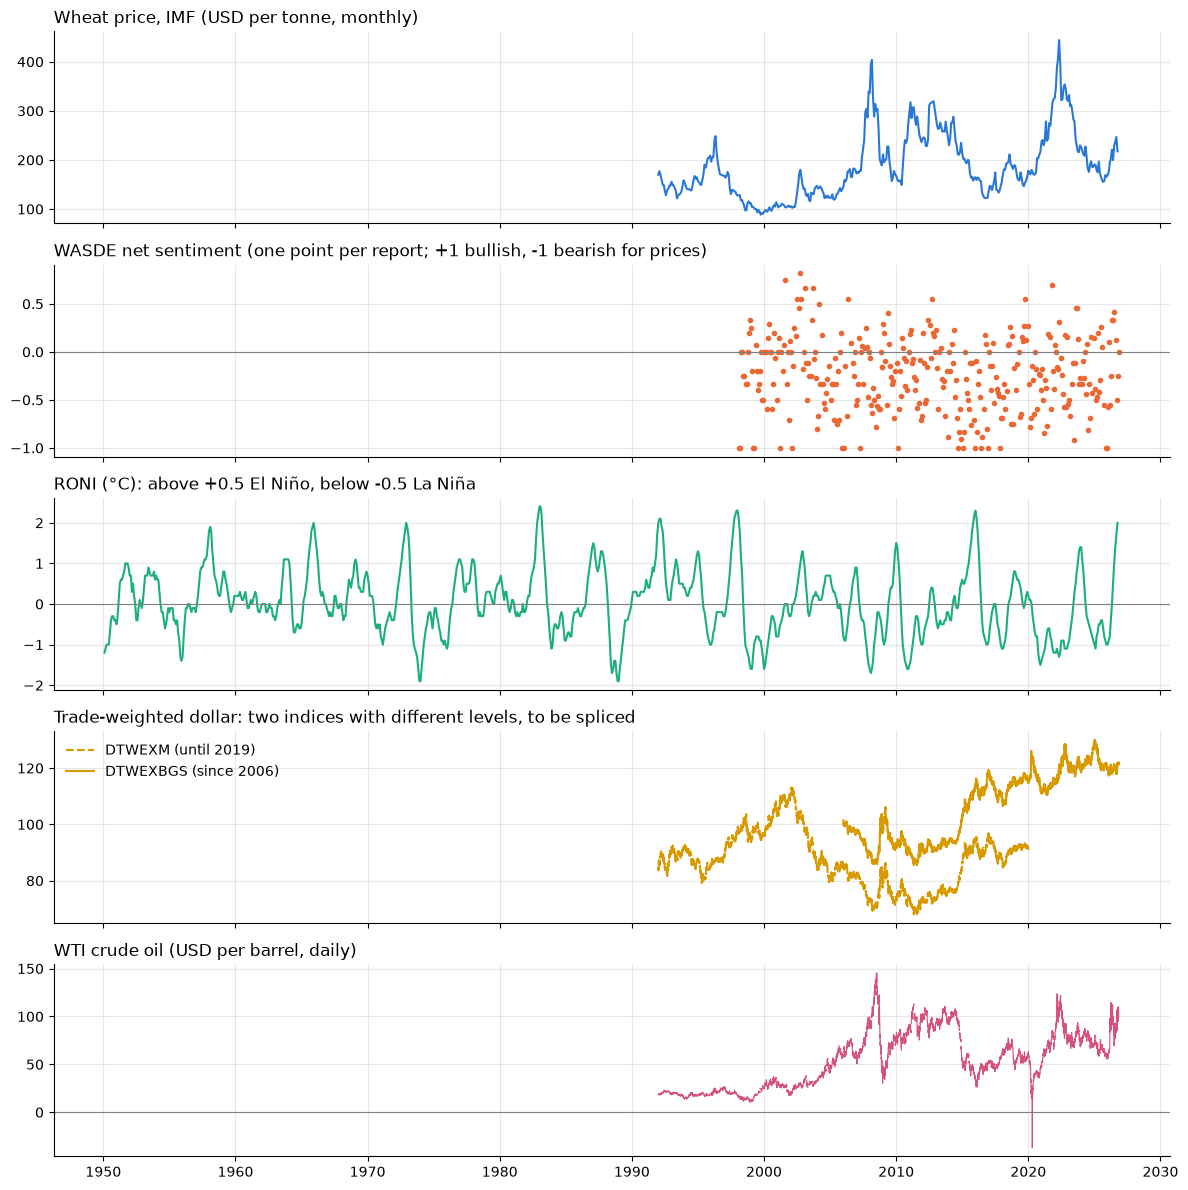

In [5]:
fig, axes = plt.subplots(5, 1, figsize=(12, 12), sharex=True)
axes[0].plot(wheat_raw["date"], wheat_raw["wheat"], color=COLORS["wheat"])
axes[0].set_title("Wheat price, IMF (USD per tonne, monthly)")
axes[1].plot(wasde["date"], wasde["sentiment"], ".", color=COLORS["sentiment"])
axes[1].set_title("WASDE net sentiment (one point per report; +1 bullish, -1 bearish for prices)")
axes[2].plot(roni_raw["date"], roni_raw["roni"], color=COLORS["roni"])
axes[2].set_title("RONI (°C): above +0.5 El Niño, below -0.5 La Niña")
axes[3].plot(dollar_old_raw["date"], dollar_old_raw["dollar_old"], "--", color=COLORS["dollar"], label="DTWEXM (until 2019)")
axes[3].plot(dollar_new_raw["date"], dollar_new_raw["dollar_new"], color=COLORS["dollar"], label="DTWEXBGS (since 2006)")
axes[3].set_title("Trade-weighted dollar: two indices with different levels, to be spliced")
axes[3].legend(loc="upper left")
axes[4].plot(wti_raw["date"], wti_raw["wti"], color=COLORS["wti"], lw=0.8)
axes[4].set_title("WTI crude oil (USD per barrel, daily)")
for ax in axes[[1, 2, 4]]:
    ax.axhline(0, color="gray", lw=0.8)
plt.tight_layout()
plt.show()

In [6]:
dated = wasde.dropna(subset=["date"])
print("WTI prices <= 0:\n", wti_raw.loc[wti_raw["wti"] <= 0].to_string(index=False))
print("WASDE reports without a date:", int(wasde["date"].isna().sum()))
print("WASDE reports without a wheat narrative, by year:",
      dated.loc[dated["sentiment"].isna(), "date"].dt.year.value_counts().sort_index().to_dict())
print("WASDE reports with a neutral score (0):", int((dated["sentiment"] == 0).sum()))
print("Day of month of the WASDE publications (expected around the 8th-12th):",
      dated["date"].dt.day.value_counts().sort_index().to_dict())

WTI prices <= 0:
       date    wti
2020-04-20 -36.98
WASDE reports without a date: 0
WASDE reports without a wheat narrative, by year: {1992: 12, 1993: 12, 1994: 12, 2008: 1}
WASDE reports with a neutral score (0): 30
Day of month of the WASDE publications (expected around the 8th-12th): {8: 27, 9: 65, 10: 92, 11: 67, 12: 119, 13: 1, 14: 2, 28: 1}


**Findings.**
- **Wheat and RONI**: no missing month.
- **FRED daily series**: missing days (holidays, and some gaps in the WTI series around 1999-2004). They do not matter once the data are averaged by month. The only negative WTI price (April 2020) is a real market event.
- **WASDE**:
  - no report for 1995-1997 was found on the USDA listing pages;
  - the 1992-1994 PDFs are scanned images without text;
  - a few months have no full report.

  These months are kept as missing values, not as a neutral score.
- **Dating check**: the publication days cluster around the 8th-12th, the usual WASDE calendar.

## 3. Data formatting
- **Monthly frequency**: monthly mean of the observations of each month; for daily series, the last month is dropped while it is still in progress.
- **Dollar**: the old index (until 2019) is chained onto the new one (since 2006) at their first common month. Their ratio is not constant, so a single scaling factor would create an artificial jump.
- **Common sample**: months where the 5 variables are observed. The variables are then standardised (mean 0, standard deviation 1) to be compared on the same scale.

In [7]:
def to_monthly(frame, col, daily=False):
    """Monthly mean; for a daily series the last month is dropped if it is still in progress."""
    s = frame[["date", col]].dropna().set_index("date")[col].sort_index()
    grouped = s.groupby(s.index.to_period("M").to_timestamp())
    monthly, counts = grouped.mean(), grouped.size()
    if daily and counts.iloc[-1] < 0.7 * counts.median():
        monthly = monthly.iloc[:-1]
    return monthly

dollar_old = to_monthly(dollar_old_raw, "dollar_old", daily=True)
dollar_new = to_monthly(dollar_new_raw, "dollar_new", daily=True)
junction = dollar_new.index[0]                                  # first common month
dollar = dollar_new.combine_first(dollar_old * dollar_new[junction] / dollar_old[junction])

monthly = pd.concat({"wheat": to_monthly(wheat_raw, "wheat"), "sentiment": to_monthly(wasde, "sentiment"),
                     "roni": to_monthly(roni_raw, "roni"), "dollar": dollar,
                     "wti": to_monthly(wti_raw, "wti", daily=True)}, axis=1, sort=True).loc[START:].asfreq("MS")

display(pd.DataFrame({"first month": monthly.apply(lambda s: s.first_valid_index()).dt.strftime("%Y-%m"),
                      "last month": monthly.apply(lambda s: s.last_valid_index()).dt.strftime("%Y-%m"),
                      "months": monthly.notna().sum(),
                      "gaps inside": monthly.apply(lambda s: s[s.first_valid_index():s.last_valid_index()].isna().sum())}))

,first month,last month,months,gaps inside
wheat,1992-01,2026-10,418,0
sentiment,1998-02,2026-11,336,10
roni,1992-01,2026-10,418,0
dollar,1992-01,2026-10,418,0
wti,1992-01,2026-10,418,0


Common sample: 335 months (1998-02 -> 2026-10); months missing inside: ['2001-05', '2002-05', '2002-11', '2004-11', '2006-03', '2006-06', '2006-07', '2013-10', '2019-01', '2025-10']


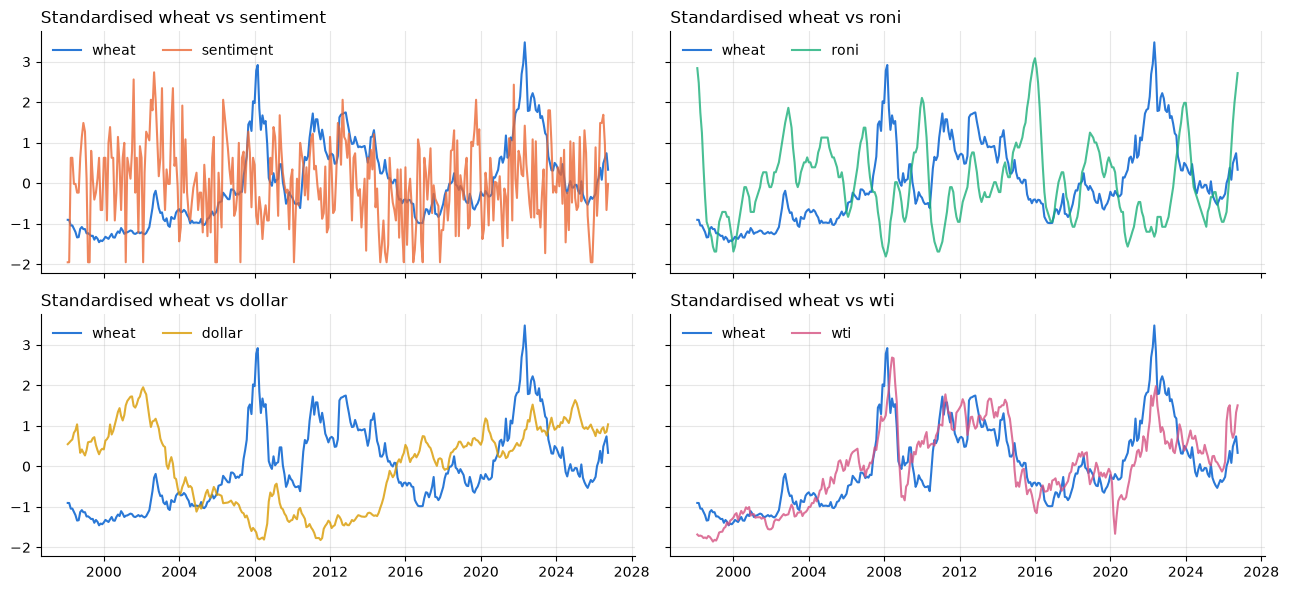

In [8]:
panel = monthly.dropna()                                        # common sample
z = (panel - panel.mean()) / panel.std()                        # standardised variables
holes = pd.date_range(panel.index[0], panel.index[-1], freq="MS").difference(panel.index)
print(f"Common sample: {len(panel)} months ({panel.index[0]:%Y-%m} -> {panel.index[-1]:%Y-%m}); "
      f"months missing inside: {[f'{d:%Y-%m}' for d in holes]}")

fig, axes = plt.subplots(2, 2, figsize=(13, 6), sharex=True, sharey=True)
for ax, c in zip(axes.flat, VARS[1:]):
    ax.plot(z["wheat"], color=COLORS["wheat"], label="wheat")
    ax.plot(z[c], color=COLORS[c], label=c, alpha=0.8)
    ax.set_title(f"Standardised wheat vs {c}")
    ax.legend(loc="upper left", ncol=2)
plt.tight_layout()
plt.show()

In [9]:
# Extreme monthly moves (log changes for prices, differences for sentiment and RONI), robust z-score
moves = pd.DataFrame({c: np.log(monthly[c]).diff() if c in PRICES else monthly[c].diff() for c in VARS})
robust_z = 0.6745 * (moves - moves.median()) / (moves - moves.median()).abs().median()
extremes = robust_z.stack()
display(extremes[extremes.abs() > 4].sort_values(key=abs, ascending=False).head(10).round(2).rename("robust z-score").to_frame())

,,robust z-score
date,,
2020-04-01,wti,-7.51
2020-03-01,wti,-7.25
2020-05-01,wti,6.89
2008-10-01,dollar,5.08
1998-06-01,roni,-4.72
2008-12-01,wti,-4.46
2008-10-01,wheat,-4.39
2026-03-01,wti,4.33
2012-07-01,wheat,4.28


The largest moves are real market events (2008 financial crisis, oil collapse of 2020, wheat drought rally of 2012) and are kept. The RONI moves look extreme only because the index changes slowly in steps of 0.1 °C.

## 4. Exploratory analysis: correlations
Prices trend over time, so two price series can look correlated without any real link (spurious correlation). Correlations are therefore also computed on **monthly changes**: log changes for the prices; sentiment and RONI stay in levels as they fluctuate around a mean.

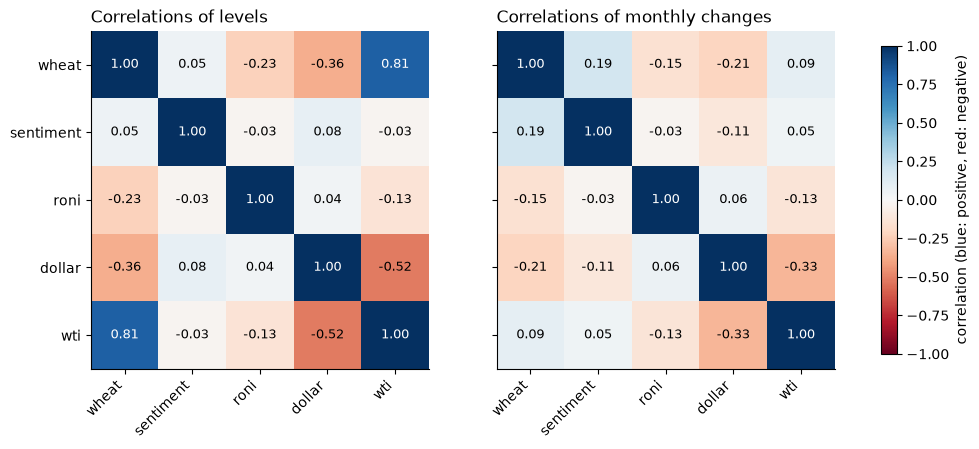

In [10]:
changes = pd.DataFrame({c: np.log(monthly[c]).diff() if c in PRICES else monthly[c] for c in VARS})

def heatmap(ax, corr, title, row_labels=True):
    image = ax.imshow(corr, cmap="RdBu", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(corr)), corr.index if row_labels else [])
    for i in range(len(corr)):
        for j in range(len(corr)):
            value = corr.iloc[i, j]
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=9,
                    color="white" if abs(value) > 0.6 else "black")     # readable on dark cells
    ax.set_title(title)
    ax.grid(False)
    return image

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
heatmap(axes[0], panel.corr(), "Correlations of levels")
image = heatmap(axes[1], changes.dropna().corr(), "Correlations of monthly changes", row_labels=False)
fig.colorbar(image, ax=axes, shrink=0.8, label="correlation (blue: positive, red: negative)")
plt.show()

**Lagged correlations.** Correlation between the wheat change of month *t* and each variable in month *t − k*. For *k* > 0 the variable leads wheat, which is what a forecast needs. Coloured bars exceed the 5 % significance threshold (grey band).

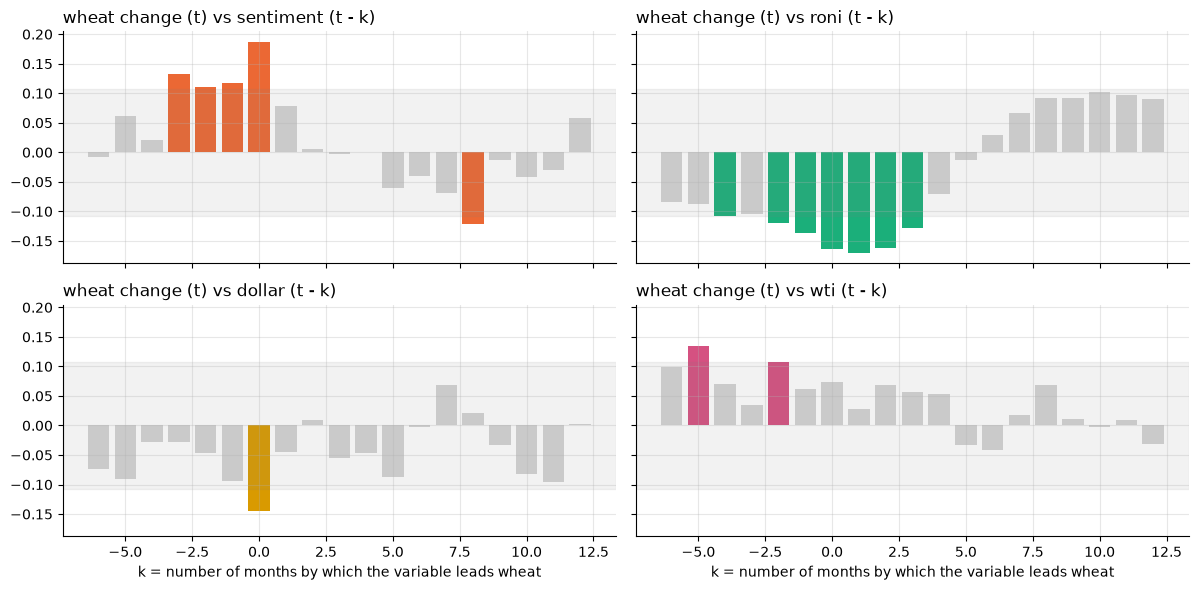

,mean,std,count
roni,,,
La Niña,0.0126,0.0689,157
neutral,-0.0018,0.0737,173
El Niño,-0.0169,0.0495,86


In [11]:
LAGS = range(-6, 13)
band = 1.96 / np.sqrt(len(changes.dropna()))
lag_corr = pd.DataFrame({c: [changes["wheat"].corr(changes[c].shift(k)) for k in LAGS] for c in VARS[1:]}, index=LAGS)

fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True, sharey=True)
for ax, c in zip(axes.flat, lag_corr):
    ax.bar(lag_corr.index, lag_corr[c], color=[COLORS[c] if abs(v) > band else "lightgray" for v in lag_corr[c]])
    ax.axhspan(-band, band, color="gray", alpha=0.1)
    ax.set_title(f"wheat change (t) vs {c} (t - k)")
for ax in axes[1]:
    ax.set_xlabel("k = number of months by which the variable leads wheat")
plt.tight_layout()
plt.show()

# Non-linear climate effect: wheat change by ENSO regime, RONI known two months before
regime = pd.cut(monthly["roni"].shift(2), [-np.inf, -0.5, 0.5, np.inf], labels=["La Niña", "neutral", "El Niño"])
display(changes["wheat"].groupby(regime, observed=True).agg(["mean", "std", "count"]).round(4))

**Stability over time.** A correlation measured over 30 years can hide regime changes; the 60-month rolling correlation shows how each link evolves.

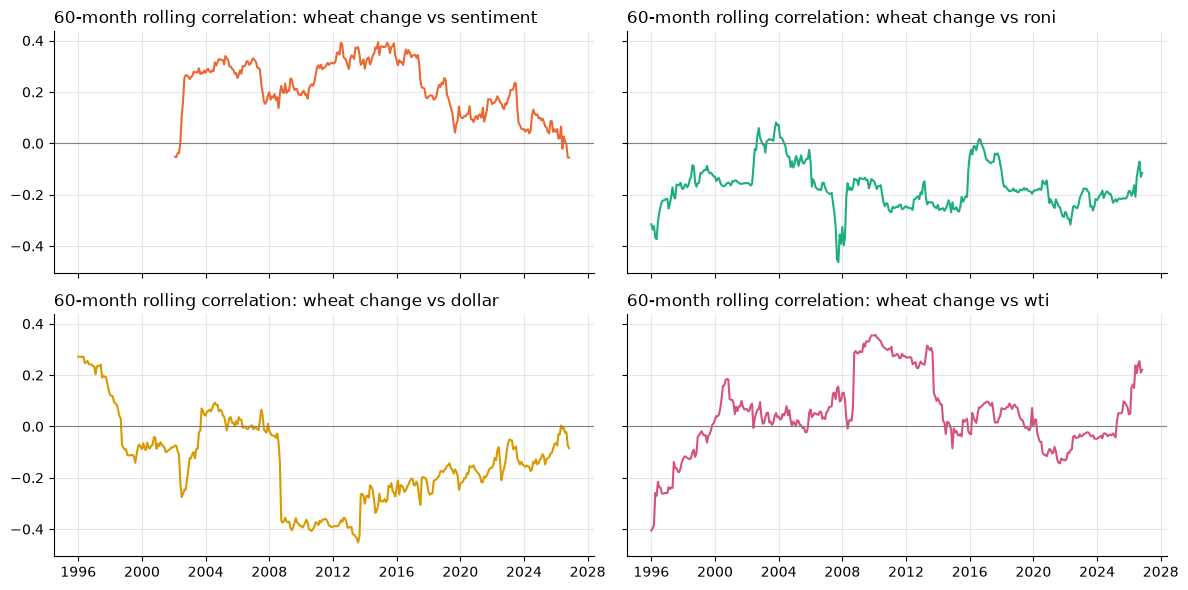

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True, sharey=True)
for ax, c in zip(axes.flat, VARS[1:]):
    ax.plot(changes["wheat"].rolling(60, min_periods=48).corr(changes[c]), color=COLORS[c])
    ax.axhline(0, color="gray", lw=0.8)
    ax.set_title(f"60-month rolling correlation: wheat change vs {c}")
plt.tight_layout()
plt.show()

## 5. Model
The model forecasts the **wheat log return of the next month** using only information available at the time of the decision:

$$\Delta\log P_{t+1} = a + b_1\,\Delta\log \text{WTI}_{t-1} + b_2\,\Delta\log \text{Dollar}_{t-1} + b_3\,\text{Sentiment}_{t-1} + b_4\,\text{ElNiño}_{t-2} + b_5\,\text{LaNiña}_{t-2} + b_6\,\Delta\text{RONI}_{t-2} + \varepsilon$$

- **Climate.** The RONI enters through three variables built on the NOAA definition of ENSO episodes (±0.5 °C):
  - **El Niño** = max(RONI − 0.5, 0), the intensity of a warm episode;
  - **La Niña** = max(−0.5 − RONI, 0), the intensity of a cold episode;
  - **ΔRONI**, the monthly change of the RONI.

  A neutral RONI therefore has no effect, and warm and cold episodes can act differently.
- **Lags.** Each variable is taken at its last value known at the decision: month *t − 1* for oil, dollar and sentiment, month *t − 2* for the RONI, which is published one month later. A month without a WASDE report keeps the last published score.
- **Estimators.** Ordinary least squares (**OLS**), **Ridge** (penalty on squared coefficients, shrinks them all) and **Lasso** (penalty on absolute coefficients, can set some to zero). For Ridge and Lasso, the variables are standardised and the penalty is chosen by time-series cross-validation inside the training data.
- **Out-of-sample test.** Training on the first 70 % of the months, test on the last 30 %. One month is dropped between the two: its target is only known after the first test decision. The benchmark is the same OLS model with the RONI as a single linear term.

In [13]:
def make_model_data(monthly):
    """Row t: target y = wheat log return from t to t+1; features are all known at the end of month t-1."""
    roni = monthly["roni"]
    features = {   # name: (series, lag in months)
        "wti_change": (np.log(monthly["wti"]).diff(), 1),
        "dollar_change": (np.log(monthly["dollar"]).diff(), 1),
        "sentiment": (monthly["sentiment"].ffill(), 1),          # last published report
        "roni": (roni, 2),
        "el_nino": ((roni - 0.5).clip(lower=0), 2),
        "la_nina": ((-0.5 - roni).clip(lower=0), 2),
        "roni_change": (roni.diff(), 2),
    }
    log_wheat = np.log(monthly["wheat"])
    data = pd.DataFrame({"y": log_wheat.shift(-1) - log_wheat, **{n: s.shift(k) for n, (s, k) in features.items()}})
    data["vol"] = log_wheat.diff().shift(1).rolling(36).std() * np.sqrt(12)   # wheat volatility known at t-1
    return data.loc[monthly["sentiment"].first_valid_index():].dropna(subset=["y"])


def ols_newey_west(X, y, lags=12):
    """OLS coefficients and Newey-West t-statistics (robust to heteroskedasticity and autocorrelation)."""
    X = np.column_stack([np.ones(len(X)), X])
    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    scores = X * (y - X @ beta)[:, None]
    S = scores.T @ scores
    for k in range(1, lags + 1):                                 # Bartlett-weighted autocovariances
        G = scores[k:].T @ scores[:-k]
        S += (1 - k / (lags + 1)) * (G + G.T)
    bread = np.linalg.inv(X.T @ X)
    return beta, beta / np.sqrt(np.diag(bread @ S @ bread))


CLIMATE = ["wti_change", "dollar_change", "sentiment", "el_nino", "la_nina", "roni_change"]
BENCHMARK = ["wti_change", "dollar_change", "sentiment", "roni"]
ESTIMATORS = {
    "OLS": LinearRegression,
    "Ridge": lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 13), cv=TimeSeriesSplit(5))),
    "Lasso": lambda: make_pipeline(StandardScaler(), LassoCV(cv=TimeSeriesSplit(5))),
}
model_data = make_model_data(monthly)

sample = model_data.dropna()
n_train = int(0.7 * len(sample))
train, test = sample.iloc[:n_train - 1], sample.iloc[n_train:]
print(f"Train: {train.index[0]:%Y-%m} -> {train.index[-1]:%Y-%m} ({len(train)} months) | "
      f"test: {test.index[0]:%Y-%m} -> {test.index[-1]:%Y-%m} ({len(test)} months)")

def evaluate(model, cols):
    pred = model.predict(test[cols])
    return {"R² train": model.score(train[cols], train["y"]),
            "R² test": 1 - ((test["y"] - pred) ** 2).sum() / ((test["y"] - train["y"].mean()) ** 2).sum(),
            "RMSE test": np.sqrt(((test["y"] - pred) ** 2).mean()),
            "RMSE test, zero forecast": np.sqrt((test["y"] ** 2).mean()),
            "hit rate test": (np.sign(pred) == np.sign(test["y"])).mean()}

fitted = {name: make().fit(train[CLIMATE], train["y"]) for name, make in ESTIMATORS.items()}
results = {f"{name} - climate regimes": evaluate(model, CLIMATE) for name, model in fitted.items()}
results["OLS - RONI level (benchmark)"] = evaluate(LinearRegression().fit(train[BENCHMARK], train["y"]), BENCHMARK)
display(pd.DataFrame(results).T.round(3))

coefficients = {f"OLS t-stat ({label})": pd.Series(ols_newey_west(train[cols].to_numpy(), train["y"].to_numpy())[1][1:], index=cols)
                for label, cols in {"climate regimes": CLIMATE, "RONI level": BENCHMARK}.items()}
coefficients.update({f"{name} coefficient (standardised)": pd.Series(fitted[name][-1].coef_, index=CLIMATE)
                     for name in ["Ridge", "Lasso"]})
display(pd.DataFrame(coefficients).round(4))

Train: 1998-03 -> 2018-01 (239 months) | test: 2018-03 -> 2026-09 (103 months)


,R² train,R² test,RMSE test,"RMSE test, zero forecast",hit rate test
OLS - climate regimes,0.060,0.034,0.067,0.069,0.631
Ridge - climate regimes,0.040,0.028,0.068,0.069,0.621
Lasso - climate regimes,0.044,0.025,0.068,0.069,0.583
OLS - RONI level (benchmark),0.016,0.039,0.067,0.069,0.631


,OLS t-stat (climate regimes),OLS t-stat (RONI level),Ridge coefficient (standardised),Lasso coefficient (standardised)
dollar_change,0.6946,0.5950,0.0010,0.0000
el_nino,-1.9551,NaN,-0.0038,-0.0034
la_nina,-0.5791,NaN,-0.0003,-0.0000
roni,NaN,-1.8018,NaN,NaN
roni_change,-2.0108,NaN,-0.0061,-0.0089
sentiment,0.4374,0.2359,0.0006,0.0000
wti_change,0.9783,0.9537,0.0015,0.0000


The R² are small, as is usual when forecasting monthly returns of a traded commodity: most of the monthly price change is unpredictable. A model can still be useful if it gets the **sign** right more often than not, which is what the portfolio exploits.

## 6. Portfolio
The simulation runs month by month. At each date *t*, each model chooses a position $w_t \in [-1, 1]$ on wheat (fraction of capital; negative = short sale), with an ex-ante annualised volatility at most equal to a **risk target σ**. Four targets are tested: 10 %, 15 %, 20 % and 25 %. They are fixed in advance, not chosen from the results.

**Timing (no look-ahead).**

| When | What happens |
|---|---|
| end of month *t − 1* | wheat, oil, dollar and sentiment are known up to *t − 1*, RONI up to *t − 2*; the position $w_t$ is computed |
| month *t* | the position is built at the average price of the month $P_t$ |
| month *t + 1* | it is closed at the average price $P_{t+1}$: return $R_{t+1} = P_{t+1}/P_t - 1$ |

The IMF prices are monthly averages: a decision taken at the end of month *t − 1* cannot be executed at the average price of month *t − 1*, which is already past.

**Position.**
1. **Forecast** $\hat y_t$ by the model of part 5, **re-estimated every month** on the rows whose target is already known (*s* ≤ *t − 2*). For Ridge and Lasso, standardisation and penalty are re-chosen each month on these rows only.
2. **Conviction** $c_t = \tanh\big((\hat y_t - m_t)/s_t\big)$, with $m_t$, $s_t$ the mean and standard deviation of the model's forecasts on its training data: an unusually high (low) forecast gives a conviction close to +1 (−1).
3. **Risk targeting** $w^*_t = \text{clip}(c_t \cdot \sigma / \hat\sigma_t, -1, 1)$, with $\hat\sigma_t$ the wheat volatility over the last 36 known months.
4. **Smoothing** $w_t = 0.5\, w_{t-1} + 0.5\, w^*_t$, to limit trading costs.

**Benchmarks.**
- **Buy & hold**: $1 of wheat kept from the first date.
- **Random walks**: 1,000 positions following a random walk $u_t = \text{clip}(u_{t-1} + \varepsilon_t, -1, 1)$, with $\varepsilon_t \sim N(0, 0.25^2)$, scaled by $\sigma/\hat\sigma_t$ like the models.

Costs are 10 basis points per unit of position traded; cash earns 0 %. Statistics are computed over the trading period (from the first position), for all strategies.

In [14]:
SIGMAS = [0.10, 0.15, 0.20, 0.25]   # annualised risk targets
MIN_TRAIN = 60                     # months of training before the first position
SMOOTH = 0.5                       # weight of the previous position in the smoothing
COST = 0.001                       # cost per unit of position traded (10 basis points)

def walk_forward(data, make_model):
    """For each month t: fit on the rows s <= t-2 (targets already known) and forecast row t."""
    out = pd.DataFrame(np.nan, index=data.index, columns=["forecast", "mean", "std"])
    for i, t in enumerate(data.index):
        past = data.iloc[:max(i - 1, 0)].dropna(subset=CLIMATE + ["y"])
        if len(past) < MIN_TRAIN or data.loc[t, CLIMATE].isna().any():
            continue
        model = make_model().fit(past[CLIMATE], past["y"])
        in_sample = model.predict(past[CLIMATE])
        out.loc[t] = model.predict(data.loc[[t], CLIMATE])[0], in_sample.mean(), in_sample.std()
    return out

def position(forecasts, data, sigma):
    """Conviction in [-1, 1], scaled to the risk target, capped at +/-1, then smoothed."""
    conviction = np.tanh((forecasts["forecast"] - forecasts["mean"]) / forecasts["std"].replace(0, np.nan))
    target = (conviction * sigma / data["vol"]).clip(-1, 1).fillna(0)
    return target.ewm(alpha=1 - SMOOTH, adjust=False).mean()   # w_t = 0.5 w_{t-1} + 0.5 w*_t

forecasts = {name: walk_forward(model_data, make) for name, make in ESTIMATORS.items()}   # do not depend on sigma
first = max(f["forecast"].first_valid_index() for f in forecasts.values())               # first trading month
R = np.exp(model_data["y"]) - 1                    # wheat return earned by the position decided at t

rng = np.random.default_rng(0)                      # random-walk exposures, drawn once for all targets
steps = rng.normal(0, 0.25, (len(model_data), 1000))
walks = np.zeros_like(steps)
for i in range(1, len(walks)):
    walks[i] = np.clip(walks[i - 1] + steps[i], -1, 1)
walks = pd.DataFrame(walks, index=model_data.index)
print(f"Decisions {model_data.index[0]:%Y-%m} -> {model_data.index[-1]:%Y-%m}; first position in {first:%Y-%m}")

Decisions 1998-02 -> 2026-09; first position in 2003-04


In [15]:
def pnl(w):
    """Monthly return: position x wheat return, minus costs on position changes."""
    return w.mul(R, axis=0) - COST * w.diff().abs().fillna(w.abs())

def stats(p):
    p = p.loc[first:]
    value = (1 + p).cumprod()
    return pd.Series({"annual return": value.iloc[-1] ** (12 / len(p)) - 1, "volatility": p.std() * np.sqrt(12),
                      "Sharpe": p.mean() / p.std() * np.sqrt(12), "max drawdown": (value / value.cummax() - 1).min()})

def wealth(p):
    """Value of $1 invested; the return of row t is earned at t+1."""
    value = (1 + p).cumprod()
    value.index = value.index + pd.offsets.MonthBegin(1)
    return pd.concat([p.iloc[:1] * 0 + 1, value])

rows, results = {}, {}
for sigma in SIGMAS:
    positions = pd.DataFrame({name: position(f, model_data, sigma) for name, f in forecasts.items()})
    scale = (sigma / model_data["vol"]).clip(upper=1) * (model_data.index >= first)
    random_pnl = pnl(walks.mul(scale, axis=0).fillna(0))
    random_stats = random_pnl.apply(stats)
    pnls = {"Buy & hold": R, **{name: pnl(positions[name]) for name in positions}}
    for name, p in pnls.items():
        s = stats(p)
        rows[(f"{sigma:.0%}", name)] = {**s, "random walks with a higher Sharpe": (random_stats.loc["Sharpe"] >= s["Sharpe"]).mean()}
    rows[(f"{sigma:.0%}", "Random walk (median)")] = random_stats.median(axis=1)
    results[sigma] = {"positions": positions, "random": wealth(random_pnl),
                      "values": pd.DataFrame({name: wealth(p) for name, p in pnls.items()})}

summary = pd.DataFrame(rows).T.rename_axis(["risk target σ", "strategy"])
display(summary.round(3))

Sharpe  annual return  max drawdown  \
risk target σ strategy                                                    
10%           Buy & hold             0.217          0.023        -0.697   
              OLS                    0.729          0.036        -0.092   
              Ridge                  0.729          0.035        -0.091   
              Lasso                  0.600          0.026        -0.130   
              Random walk (median)  -0.019         -0.004        -0.384   
15%           Buy & hold             0.217          0.023        -0.697   
              OLS                    0.729          0.053        -0.136   
              Ridge                  0.729          0.052        -0.134   
              Lasso                  0.600          0.039        -0.190   
              Random walk (median)  -0.019         -0.007        -0.525   
20%           Buy & hold             0.217          0.023        -0.697   
              OLS                    0.727          0.069        -0.179   
              Ridge                  0.728          0.068        -0.176   
              Lasso                  0.601          0.051        -0.247   
              Random walk (median)  -0.012         -0.011        -0.628   
25%           Buy & hold             0.217          0.023        -0.697   
              OLS                    0.734          0.084        -0.195   
              Ridge                  0.735          0.083        -0.193   
              Lasso                  0.630          0.065        -0.265   
              Random walk (median)  -0.012         -0.014        -0.671   

                                    random walks with a higher Sharpe  \
risk target σ strategy                                                  
10%           Buy & hold                                        0.191   
              OLS                                               0.001   
              Ridge                                             0.001   
              Lasso                                             0.004   
              Random walk (median)                                NaN   
15%           Buy & hold                                        0.191   
              OLS                                               0.001   
              Ridge                                             0.001   
              Lasso                                             0.004   
              Random walk (median)                                NaN   
20%           Buy & hold                                        0.181   
              OLS                                               0.001   
              Ridge                                             0.001   
              Lasso                                             0.003   
              Random walk (median)                                NaN   
25%           Buy & hold                                        0.172   
              OLS                                               0.001   
              Ridge                                             0.001   
              Lasso                                             0.001   
              Random walk (median)                                NaN   

                                    volatility  
risk target σ strategy                          
10%           Buy & hold                 0.254  
              OLS                        0.050  
              Ridge                      0.049  
              Lasso                      0.045  
              Random walk (median)       0.070  
15%           Buy & hold                 0.254  
              OLS                        0.075  
              Ridge                      0.073  
              Lasso                      0.068  
              Random walk (median)       0.106  
20%           Buy & hold                 0.254  
              OLS                        0.099  
              Ridge                      0.097  
              Lasso                      0.

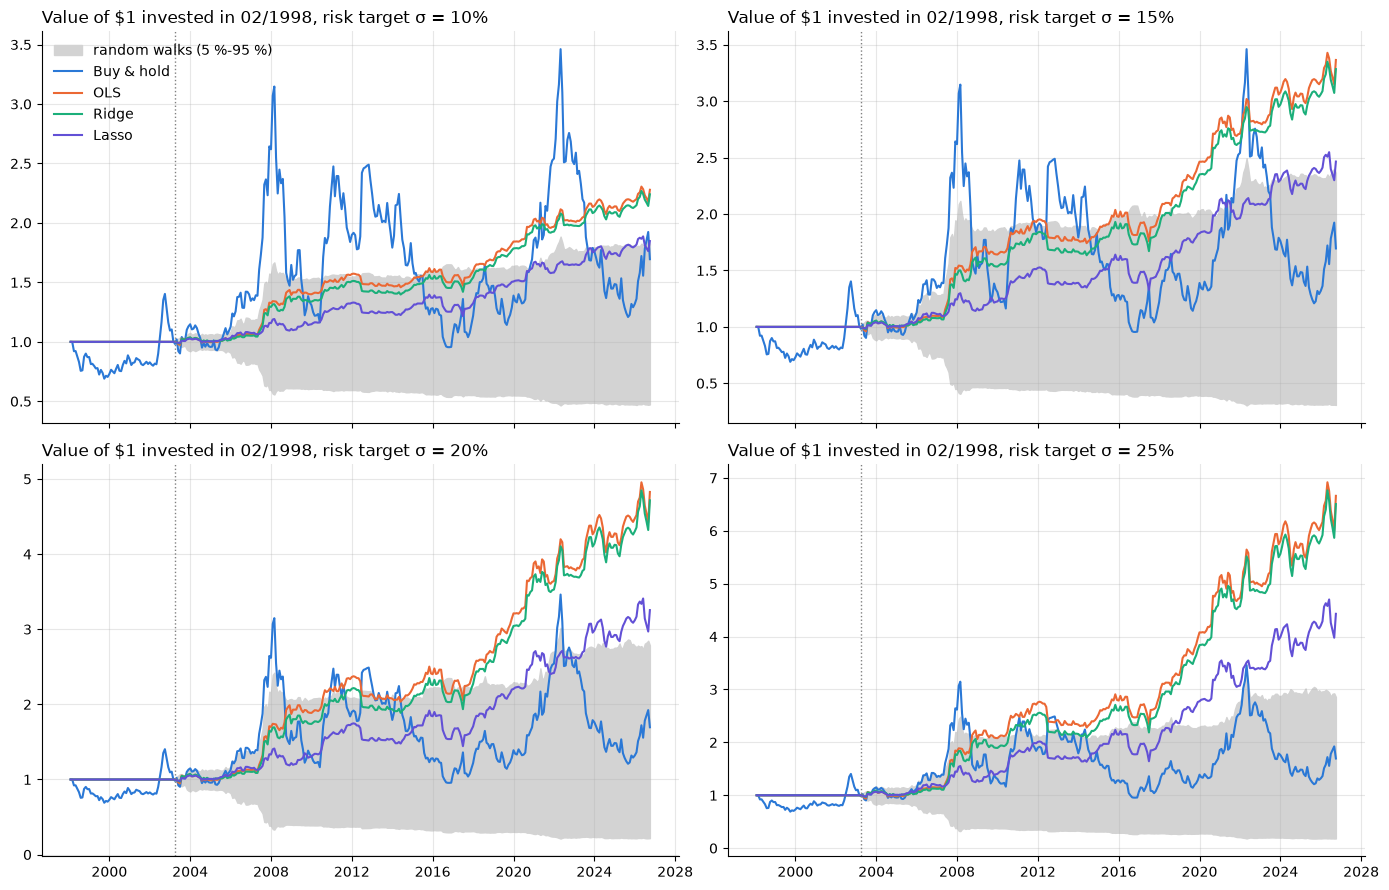

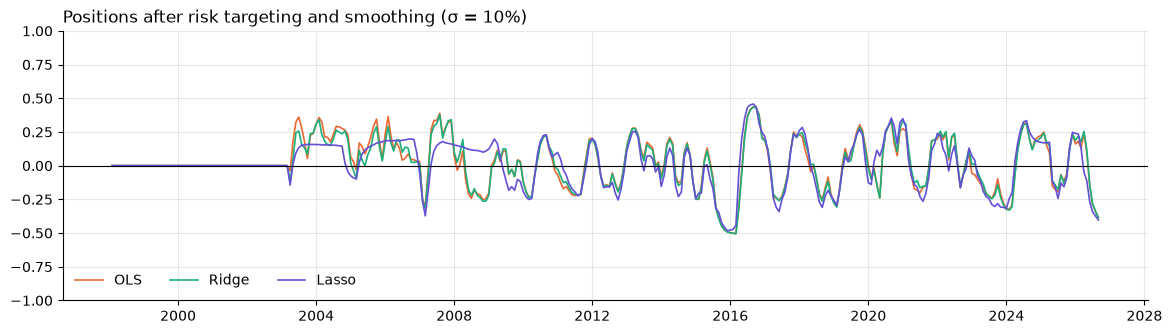

realised volatility               Sharpe              
strategy                      OLS  Ridge  Lasso    OLS  Ridge  Lasso
risk target σ                                                       
10%                         0.050  0.049  0.045  0.729  0.729  0.600
15%                         0.075  0.073  0.068  0.729  0.729  0.600
20%                         0.099  0.097  0.091  0.727  0.728  0.601
25%                         0.120  0.118  0.110  0.734  0.735  0.630

In [16]:
STYLE = {"Buy & hold": "#2a78d6", "OLS": "#eb6834", "Ridge": "#1baf7a", "Lasso": "#6250d6"}
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
for ax, sigma in zip(axes.flat, SIGMAS):
    res = results[sigma]
    ax.fill_between(res["random"].index, res["random"].quantile(0.05, axis=1), res["random"].quantile(0.95, axis=1),
                    color="lightgray", label="random walks (5 %-95 %)")
    for name, color in STYLE.items():
        ax.plot(res["values"][name], color=color, label=name)
    ax.axvline(first, color="gray", ls=":", lw=1)
    ax.set_title(f"Value of $1 invested in {model_data.index[0]:%m/%Y}, risk target σ = {sigma:.0%}")
axes[0, 0].legend(loc="upper left")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(14, 3.5))
for name in ESTIMATORS:
    ax.plot(results[SIGMAS[0]]["positions"][name], color=STYLE[name], lw=1.2, label=name)
ax.axhline(0, color="black", lw=0.8)
ax.set_ylim(-1, 1)
ax.set_title(f"Positions after risk targeting and smoothing (σ = {SIGMAS[0]:.0%})")
ax.legend(loc="lower left", ncol=3)
plt.show()

# Realised volatility vs risk target, and Sharpe ratio, for each model
models = list(ESTIMATORS)
display(pd.concat({"realised volatility": summary["volatility"].unstack()[models],
                   "Sharpe": summary["Sharpe"].unstack()[models]}, axis=1).round(3))

**Reading the results.**
- **Risk use.** The realised volatility stays below the target: the conviction rarely reaches ±1 and the smoothing shrinks the positions further. The risk constraint is respected ex ante but not fully used.
- **Sharpe ratio.** All positions are proportional to σ, so changing the target scales gains and losses but leaves the Sharpe ratio almost unchanged. The choice of σ sets the level of risk taken; it does not create performance.
- **Random walks.** The share of random walks with a higher Sharpe measures how likely the result is to be luck.

**Look-ahead check (placebo test).** All the data from `T0` onwards are replaced by noise and the models are run again. If no future information is used, every position decided up to `T0` must stay identical.

In [17]:
T0 = pd.Timestamp("2015-01-01")
noisy = monthly.copy()
after = noisy.index >= T0
noisy.loc[after] = noisy.loc[after].mask(noisy.loc[after].notna(),
                                         np.random.default_rng(1).uniform(10, 100, noisy.loc[after].shape))
noisy_data = make_model_data(noisy)
for name, make in ESTIMATORS.items():
    check = position(walk_forward(noisy_data, make), noisy_data, SIGMAS[0])
    reference = results[SIGMAS[0]]["positions"][name]
    print(f"{name}: positions up to {T0:%Y-%m} unchanged: {np.allclose(check[:T0], reference[:T0])}; "
          f"later positions changed: {not np.allclose(check[T0:].iloc[1:], reference[T0:].iloc[1:])}")

OLS: positions up to 2015-01 unchanged: True; later positions changed: True


Ridge: positions up to 2015-01 unchanged: True; later positions changed: True


Lasso: positions up to 2015-01 unchanged: True; later positions changed: True


**Limitations.**
- **Execution**: at the average price of the month, without futures roll costs; cash earns 0 %; short sales are free; trading costs of 10 basis points are an assumption.
- **Model choice**: the El Niño / La Niña coding was suggested by an analysis on the same data. Some selection bias is therefore possible, and the stability of the results over sub-periods should be checked.
- **Sentiment**: the word lists are simple and some words are ambiguous (e.g. *lower* can refer to prices or to production).
- **Data**: current vintages are used, not the values published at the time (the IMF prices and the RONI can be revised).
- **Statistics**: about 23 years of monthly data is a short sample to measure a Sharpe ratio precisely.